# PaySim Fraud Dataset: Data Audit

**Question:** Can this dataset support a fraud detection model built on information available at the time of payment?

**Answer:** Only weakly. Almost all fraud follows a simulator pattern in the sender's balance, and several other columns carry simulator artifacts. Once those are excluded, point-in-time destination history shows a modest predictive association in this PaySim release. Its generalizability and underlying cause remain unverified.

**Data:** PaySim synthetic mobile money transactions (Lopez-Rojas et al., 2016), 6.36M transactions over 744 hours.

## 1. Load data and check structure

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PARQUET = "../data/processed/paysim.parquet"
CSV = "../data/raw/paysim.csv"

# Convert the CSV to Parquet once; later runs load the faster Parquet file
if not os.path.exists(PARQUET):
    pd.read_csv(CSV).to_parquet(PARQUET, index=False)

df = pd.read_parquet(PARQUET)
df["hour"] = df["step"] % 24
df["day"] = df["step"] // 24

print(df.shape)
print(df.dtypes)
print(df.isna().sum())

(6362620, 13)
step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
hour                int64
day                 int64
dtype: object
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
hour              0
day               0
dtype: int64


**Finding:** 6,362,620 rows, 11 original columns, no missing values. Rows are already in chronological order of `step` (1 step = 1 hour).

In [2]:
print("Rows in chronological order:", df["step"].is_monotonic_increasing)

Rows in chronological order: True


## 2. Class balance by transaction type

In [3]:
print("Overall fraud rate:", df["isFraud"].mean())

by_type = df.groupby("type").agg(
    transactions=("isFraud", "size"),
    frauds=("isFraud", "sum"),
    fraud_rate=("isFraud", "mean"),
)
by_type

Overall fraud rate: 0.001290820448180152


,transactions,frauds,fraud_rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.001840
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.007688


**Finding:** Overall fraud rate is 0.13%. Fraud occurs only in TRANSFER (4,097 cases, 0.77% rate) and CASH_OUT (4,116 cases, 0.18%). CASH_IN, DEBIT and PAYMENT contain no fraud.

## 3. Existing controls

In [4]:
tc_mask = df["type"].isin(["TRANSFER", "CASH_OUT"])
total_fraud_count = df["isFraud"].sum()
total_fraud_value = df.loc[df["isFraud"] == 1, "amount"].sum()
n_days = df["day"].nunique()

def rule_performance(flag, name):
    flagged = df[flag]
    caught = flagged["isFraud"].sum()
    caught_value = flagged.loc[flagged["isFraud"] == 1, "amount"].sum()
    return {
        "rule": name,
        "alerts": len(flagged),
        "alerts_per_day": round(len(flagged) / n_days, 1),
        "frauds_caught": caught,
        "false_alarms": len(flagged) - caught,
        "precision_%": round(100 * caught / len(flagged), 2) if len(flagged) else 0,
        "fraud_count_caught_%": round(100 * caught / total_fraud_count, 1),
        "fraud_value_caught_%": round(100 * caught_value / total_fraud_value, 1),
    }

rules = pd.DataFrame([
    rule_performance(df["isFlaggedFraud"] == 1, "isFlaggedFraud column"),
    rule_performance((df["type"] == "TRANSFER") & (df["amount"] > 200_000), "Documented rule: TRANSFER > 200,000"),
])
rules

,rule,alerts,alerts_per_day,frauds_caught,false_alarms,precision_%,fraud_count_caught_%,fraud_value_caught_%
0,isFlaggedFraud column,16,0.5,16,0,100.00,0.2,0.6
1,"Documented rule: TRANSFER > 200,000",409110,13197.1,2740,406370,0.67,33.4,49.4


**Finding: the existing controls are either precise but blind, or broad but unworkable.**
- `isFlaggedFraud`: 16 alerts in 31 days (~0.5/day), 100% precision, but only 0.2% of fraud cases and 0.6% of fraud value caught.
- Documented rule (TRANSFER > 200,000): 409,110 alerts (~13,200/day), 0.67% precision, 33.4% of fraud cases and 49.4% of fraud value caught.
- The `isFlaggedFraud` column does not match its documented rule: 409,110 transfers exceed 200,000 but only 16 are flagged.

## 4. Amount: fraud vs legitimate

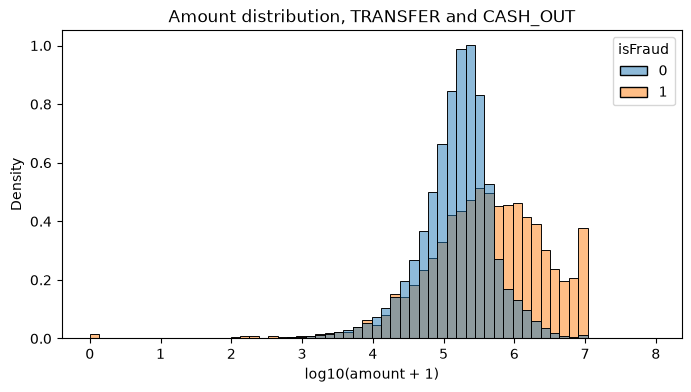

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,2762196.0,3.141155e+05,8.771441e+05,0.01,82908.2325,171034.46,305994.185,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.3300,441423.44,1517771.480,10000000.00


In [5]:
sub = df.loc[df["type"].isin(["TRANSFER", "CASH_OUT"]), ["amount", "isFraud"]]

plt.figure(figsize=(8, 4))
sns.histplot(data=sub, x=np.log10(sub["amount"] + 1), hue="isFraud",
             stat="density", common_norm=False, bins=60)
plt.xlabel("log10(amount + 1)")
plt.title("Amount distribution, TRANSFER and CASH_OUT")
plt.show()

sub.groupby("isFraud")["amount"].describe()

**Finding:** Fraud amounts are larger on average (median 441,423 vs 171,034 for legitimate TRANSFER/CASH_OUT) but overlap heavily: the middle half of fraud falls between 127,091 and 1,517,771, a range that covers most legitimate transactions above the median (legitimate 75th percentile: 305,994). Amount alone does not separate fraud from legitimate activity. No fraud amount exceeds 10,000,000, while legitimate amounts reach 92.4 million.

## 5. Time patterns

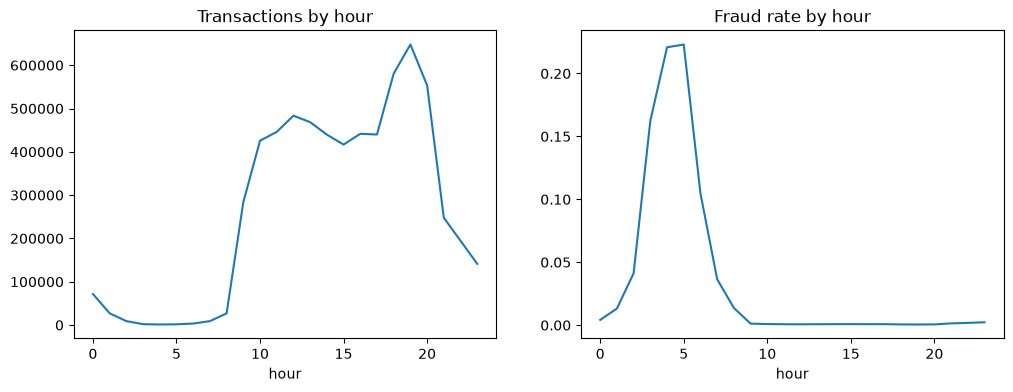

,transactions,frauds
day,,
0,571039,265
1,452761,305
2,6749,306
3,21904,272
4,12995,244
5,440626,230
6,420282,280
7,449147,270
8,418103,259


In [6]:
hourly = df.groupby("hour").agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"))
hourly["fraud_rate"] = hourly["frauds"] / hourly["transactions"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
hourly["transactions"].plot(ax=ax[0], title="Transactions by hour")
hourly["fraud_rate"].plot(ax=ax[1], title="Fraud rate by hour")
plt.show()

daily = df.groupby("day").agg(transactions=("isFraud", "size"), frauds=("isFraud", "sum"))
daily

**Finding: fraud is injected at a near-constant rate, while overall activity varies.**
- By hour: total volume drops to near zero in the early hours while fraud continues, so the fraud rate spikes there (right panel).
- By day: total volume is 350k–571k on days 0–1 and 5–16, but only 6.7k–59k on days 2–4 and 17–29. Fraud stays at 220–316 per day throughout.
- Day 30 contains 282 transactions, all fraud.

**Implication:** the signal in `step`, `day` and `hour` is heavily confounded by the simulator's volume pattern. These columns are excluded from any baseline here; including them later would need a chronological holdout and evidence that the pattern is not a volume artifact.

## 6. Direct account linkage

In [7]:
fraud = df[df["isFraud"] == 1]

transfer_dest = set(fraud.loc[fraud["type"] == "TRANSFER", "nameDest"])
cashout_orig = set(fraud.loc[fraud["type"] == "CASH_OUT", "nameOrig"])
print("Fraud TRANSFER destinations that later originate a fraud CASH_OUT:",
      len(transfer_dest & cashout_orig))

print("Unique nameOrig share:", df["nameOrig"].nunique() / len(df))
print("Unique nameDest share:", df["nameDest"].nunique() / len(df))

print(fraud["nameDest"].value_counts().head(10))

Fraud TRANSFER destinations that later originate a fraud CASH_OUT: 0
Unique nameOrig share: 0.9985362947967975
Unique nameDest share: 0.4278680795018404
nameDest
C410033330     2
C803116137     2
C904300960     2
C1013511446    2
C2020337583    2
C200064275     2
C185805228     2
C52390890      2
C935310781     2
C1827219533    2
Name: count, dtype: int64


**Finding (narrow):**
- No destination of a fraudulent TRANSFER appears as the origin of a fraudulent CASH_OUT, so the transfer-then-cash-out chain is not directly linked among the labelled fraud transactions.
- Sender history is highly limited: the number of unique sender IDs is 99.85% of the transaction count, indicating little repetition relative to the dataset's size.
- Destinations repeat far more (the number of unique destination IDs is 42.8% of the transaction count), so destination history is worth testing (section 10). No destination receives more than two fraudulent transactions.
- This check does not test chains through legitimate intermediate transactions.

## 7. Balance columns: what is leakage and what is a simulator pattern

In [8]:
tc = df.loc[tc_mask, ["isFraud", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]]

checks = pd.DataFrame({
    # Post-transaction state
    "origin_balance_consistent (old - amount == new)": np.isclose(tc["oldbalanceOrg"] - tc["amount"], tc["newbalanceOrig"]),
    "dest_balances_both_zero": (tc["oldbalanceDest"] == 0) & (tc["newbalanceDest"] == 0),
    # Pre-transaction state
    "amount_equals_sender_balance": tc["amount"] == tc["oldbalanceOrg"],
    "sender_balance_zero_before": tc["oldbalanceOrg"] == 0,
})
balance_checks = (checks.groupby(tc["isFraud"]).mean() * 100).round(2).T.rename(columns={0: "legit_%", 1: "fraud_%"})
del tc, checks, sub   # free memory before the heavier sections
balance_checks

isFraud,legit_%,fraud_%
origin_balance_consistent (old - amount == new),9.90,99.45
dest_balances_both_zero,0.06,49.63
amount_equals_sender_balance,0.00,97.82
sender_balance_zero_before,47.37,0.50


**Finding: two different problems, which should be kept apart.**

| Column type | What the data shows | Issue |
|---|---|---|
| Post-transaction destination balances | Both zero for 49.6% of fraud vs 0.06% of legitimate transactions | Simulator artifact strongly tied to the label |
| Post-transaction origin balance | Consistent with the amount (old − amount = new) for 99.5% of fraud but only 9.9% of legitimate transactions | Still separates the classes strongly. The cancellation the dataset author describes is not what drives this |
| Pre-transaction sender balance | Known at payment time. 97.8% of fraud moves exactly the full balance vs no legitimate transactions; 47.4% of legitimate TRANSFER/CASH_OUT come from zero-balance accounts vs 0.5% of fraud | Not leakage in the strict timing sense, but a near-deterministic simulator pattern (section 8) |

The dataset author advises against using any of the four balance columns.

## 8. Does a simple rule already separate fraud?

In [9]:
draining = tc_mask & (df["amount"] == df["oldbalanceOrg"])   # exact equality
draining_close = tc_mask & np.isclose(df["amount"], df["oldbalanceOrg"])  # used in the first version

rules = pd.concat([rules, pd.DataFrame([
    rule_performance(draining, "Amount equals full sender balance (exact)"),
    rule_performance(draining_close, "Same rule with np.isclose tolerance"),
])], ignore_index=True)
rules

,rule,alerts,alerts_per_day,frauds_caught,false_alarms,precision_%,fraud_count_caught_%,fraud_value_caught_%
0,isFlaggedFraud column,16,0.5,16,0,100.00,0.2,0.6
1,"Documented rule: TRANSFER > 200,000",409110,13197.1,2740,406370,0.67,33.4,49.4
2,Amount equals full sender balance (exact),8034,259.2,8034,0,100.00,97.8,87.7
3,Same rule with np.isclose tolerance,8037,259.3,8034,3,99.96,97.8,87.7


**Finding: one balance pattern separates almost all fraud.**
With exact equality, flagging transactions where the amount equals the sender's full balance catches 97.8% of fraud cases and 87.7% of fraud value with no false alarms (8,034 alerts, ~260/day). The 3 false alarms in the first version came from `np.isclose`'s tolerance, not from the data.

This confirms an observation already reported by Visbeek et al. (2023, see README). The rule has no fitted parameters, but it was identified after examining the full dataset.

## 9. Fraud the rule misses, and the 10,000,000 amount

In [10]:
missed = df[(df["isFraud"] == 1) & ~draining]
missed_10m = missed[missed["amount"] == 10_000_000]

print("Frauds missed by the rule:", len(missed))
print("Of which exactly 10,000,000:", len(missed_10m))
print("Missed 10M frauds where sender held more than 10M:", (missed_10m["oldbalanceOrg"] > 10_000_000).sum())
print("Largest fraud amount:", df.loc[df["isFraud"] == 1, "amount"].max())
print("Legitimate transactions of exactly 10,000,000:", ((df["amount"] == 10_000_000) & (df["isFraud"] == 0)).sum())

Frauds missed by the rule: 179
Of which exactly 10,000,000: 145
Missed 10M frauds where sender held more than 10M: 145
Largest fraud amount: 10000000.0
Legitimate transactions of exactly 10,000,000: 2920


In [11]:
amount_10m = tc_mask & (df["amount"] == 10_000_000)
pd.DataFrame([
    rule_performance(draining, "Full-balance rule"),
    rule_performance(amount_10m, "Amount == 10,000,000 (standalone)"),
    rule_performance(draining | amount_10m, "Full-balance OR 10,000,000"),
])

,rule,alerts,alerts_per_day,frauds_caught,false_alarms,precision_%,fraud_count_caught_%,fraud_value_caught_%
0,Full-balance rule,8034,259.2,8034,0,100.00,97.8,87.7
1,"Amount == 10,000,000 (standalone)",3207,103.5,287,2920,8.95,3.5,23.8
2,"Full-balance OR 10,000,000",11099,358.0,8179,2920,73.69,99.6,99.8


**Finding: the 10,000,000 amount explains the misses; it is not a good detector on its own.**
- 145 of the 179 missed frauds are exactly 10,000,000, and every one of them came from an account holding more than 10,000,000. No fraud exceeds 10,000,000, which is consistent with a per-transaction limit on fraud in the simulator, so larger balances are emptied in several transfers and no single transfer equals the full balance.
- Flagging amount = 10,000,000 on its own has under 9% precision, because 2,920 legitimate transfers are also exactly 10,000,000.
- Combined with the full-balance rule, it catches 99.6% of fraud cases and 99.8% of fraud value at 73.7% precision (~358 alerts/day). Like the full-balance rule, this combination was chosen after seeing the data.
- 34 frauds (0.4%) are still missed by the combined rule.

## 9b. Stability check (not an independent evaluation)

In [12]:
rows = []
for label, m in [("days 0-14", df["day"] <= 14), ("days 15-30", df["day"] >= 15)]:
    f = df["isFraud"] == 1
    hit = draining & m
    rows.append({"period": label,
                 "alerts": hit.sum(),
                 "precision_%": round(100 * (hit & f).sum() / hit.sum(), 2),
                 "fraud_count_caught_%": round(100 * (hit & f).sum() / (f & m).sum(), 1)})
pd.DataFrame(rows)

,period,alerts,precision_%,fraud_count_caught_%
0,days 0-14,3933,100.0,98.1
1,days 15-30,4101,100.0,97.5


**Finding:** the full-balance rule performs about the same in both halves of the month. This shows the pattern is stable within this simulation run. Because the rule was chosen after looking at all the data, it is not an independent test; that would need a separate PaySim run.

## 10. Point-in-time destination-account history

For each transaction, the destination account's history is computed using **only transactions in strictly earlier steps**. PaySim does not record the order of transactions within the same hour, so same-step transactions are excluded rather than guessed. Features:
- `prior_in`, `prior_out`: earlier incoming and outgoing transactions involving the account
- `prior_in_amount`: total amount it received earlier
- `hours_since_prev`: hours since its previous transaction (empty if none)

In [13]:
def destination_history(data):
    inc = pd.DataFrame({"acct": data["nameDest"], "step": data["step"], "n_in": 1, "n_out": 0, "amt_in": data["amount"]})
    out = pd.DataFrame({"acct": data["nameOrig"], "step": data["step"], "n_in": 0, "n_out": 1, "amt_in": 0.0})
    ev = (pd.concat([inc, out], ignore_index=True)
            .groupby(["acct", "step"], as_index=False)[["n_in", "n_out", "amt_in"]].sum()
            .sort_values(["acct", "step"]))
    g = ev.groupby("acct")
    # cumulative totals minus the current step = strictly earlier steps only
    ev["prior_in"] = g["n_in"].cumsum() - ev["n_in"]
    ev["prior_out"] = g["n_out"].cumsum() - ev["n_out"]
    ev["prior_in_amount"] = g["amt_in"].cumsum() - ev["amt_in"]
    ev["prev_step"] = g["step"].shift()
    res = data[["nameDest", "step"]].merge(ev, left_on=["nameDest", "step"], right_on=["acct", "step"], how="left")
    res.index = data.index
    res["prior_events"] = res["prior_in"] + res["prior_out"]
    res["hours_since_prev"] = res["step"] - res["prev_step"]
    return res[["prior_in", "prior_out", "prior_events", "prior_in_amount", "hours_since_prev"]]

hist = destination_history(df[["step", "nameOrig", "nameDest", "amount"]])
tcx = df.loc[tc_mask, ["step", "day", "amount", "nameDest", "isFraud"]].join(hist)
del hist

**Check:** recompute all four underlying features (`prior_in`, `prior_out`, `prior_in_amount`, `hours_since_prev`) for a random sample directly from the raw rows, using only earlier steps, and confirm they match.

In [14]:
sample = pd.concat([tcx[tcx["isFraud"] == 1].sample(150, random_state=0),
                    tcx[tcx["isFraud"] == 0].sample(150, random_state=0)])
accts = set(sample["nameDest"])
raw_in = df.loc[df["nameDest"].isin(accts), ["nameDest", "step", "amount"]]   # raw rows where the account received
raw_out = df.loc[df["nameOrig"].isin(accts), ["nameOrig", "step"]]            # raw rows where the account sent

mismatches = {"prior_in": 0, "prior_out": 0, "prior_in_amount": 0, "hours_since_prev": 0}
for idx, r in sample.iterrows():
    earlier_in = raw_in[(raw_in["nameDest"] == r["nameDest"]) & (raw_in["step"] < r["step"])]
    earlier_out = raw_out[(raw_out["nameOrig"] == r["nameDest"]) & (raw_out["step"] < r["step"])]

    n_in, n_out = len(earlier_in), len(earlier_out)
    amt_in = earlier_in["amount"].sum()
    earlier_steps = pd.concat([earlier_in["step"], earlier_out["step"]])
    gap = r["step"] - earlier_steps.max() if len(earlier_steps) else np.nan

    mismatches["prior_in"] += n_in != r["prior_in"]
    mismatches["prior_out"] += n_out != r["prior_out"]
    mismatches["prior_in_amount"] += not np.isclose(amt_in, r["prior_in_amount"])
    both_missing = np.isnan(gap) and pd.isna(r["hours_since_prev"])
    mismatches["hours_since_prev"] += not (both_missing or gap == r["hours_since_prev"])

print(f"Rows checked: {len(sample)}")
print(pd.Series(mismatches, name="mismatches"))

Rows checked: 300
prior_in            0
prior_out           0
prior_in_amount     0
hours_since_prev    0
Name: mismatches, dtype: int64


**Check passed (sample):** for 300 sampled transactions (150 fraud, 150 legitimate), all four underlying features (`prior_in`, `prior_out`, `prior_in_amount`, `hours_since_prev`) match a direct recount from the raw rows with 0 mismatches.

**Full check:** recompute the four features for **every** TRANSFER and CASH_OUT row with a second, independent method. Instead of grouping and running totals, it sorts all raw transactions by account and step and counts earlier ones by binary search. Amounts are summed in integer cents, so the comparison allows at most 1 cent of floating-point difference.

In [15]:
# Full check: every TRANSFER/CASH_OUT row, recomputed with a second, independent method
# (binary search over raw transactions sorted by account and step, instead of groupby + cumsum).
n = len(df)
codes, _ = pd.factorize(pd.concat([df["nameOrig"], df["nameDest"]], ignore_index=True))
orig_code, dest_code = codes[:n].astype(np.int64), codes[n:].astype(np.int64)
step = df["step"].to_numpy().astype(np.int64)
BIG = int(step.max()) + 2                      # key = account * BIG + step sorts by account, then step

in_key = dest_code * BIG + step                # every raw row where the account received money
order = np.argsort(in_key, kind="stable")
in_sorted = in_key[order]
cents = np.round(df["amount"].to_numpy() * 100).astype(np.int64)   # integer cents: exact sums
in_cum = np.concatenate([[0], np.cumsum(cents[order])])
out_sorted = np.sort(orig_code * BIG + step)   # every raw row where the account sent money
all_sorted = np.sort(np.concatenate([in_sorted, out_sorted]))
del codes, orig_code, in_key, order, cents

m = tc_mask.to_numpy()
q_acct, q_step = dest_code[m], step[m]
start, now = q_acct * BIG, q_acct * BIG + q_step   # "now" excludes the current step and later
i_lo, i_hi = np.searchsorted(in_sorted, start), np.searchsorted(in_sorted, now)
o_lo, o_hi = np.searchsorted(out_sorted, start), np.searchsorted(out_sorted, now)
a_lo, a_hi = np.searchsorted(all_sorted, start), np.searchsorted(all_sorted, now)

check = pd.DataFrame({
    "prior_in": i_hi - i_lo,
    "prior_out": o_hi - o_lo,
    "prior_in_amount": (in_cum[i_hi] - in_cum[i_lo]) / 100,
    "hours_since_prev": np.where(a_hi > a_lo, q_step - (all_sorted[np.maximum(a_hi - 1, 0)] - start), np.nan),
}, index=tcx.index)
del dest_code, step, in_sorted, in_cum, out_sorted, all_sorted

amount_diff = (tcx["prior_in_amount"] - check["prior_in_amount"]).abs()
full_mismatches = pd.Series({
    "prior_in": (tcx["prior_in"] != check["prior_in"]).sum(),
    "prior_out": (tcx["prior_out"] != check["prior_out"]).sum(),
    "prior_in_amount": (amount_diff > 0.01).sum(),   # tolerance of 1 cent for floating-point sums
    "hours_since_prev": (~((tcx["hours_since_prev"] == check["hours_since_prev"])
                           | (tcx["hours_since_prev"].isna() & check["hours_since_prev"].isna()))).sum(),
}, name="mismatches")
print(f"Rows checked: {len(check):,} (all TRANSFER and CASH_OUT)")
print(f"Largest prior_in_amount difference: {amount_diff.max():.6f}")
print(full_mismatches)
del check, amount_diff

Rows checked: 2,770,409 (all TRANSFER and CASH_OUT)
Largest prior_in_amount difference: 0.000000
prior_in            0
prior_out           0
prior_in_amount     0
hours_since_prev    0
Name: mismatches, dtype: int64


**Check passed (all rows):** for all 2,770,409 TRANSFER and CASH_OUT rows, the independent recomputation matches all four features exactly, with 0 mismatches and a largest `prior_in_amount` difference of 0.00. The point-in-time features use only transactions from strictly earlier steps.

In [16]:
summary = tcx.groupby("isFraud").agg(
    zero_prior_events_pct=("prior_events", lambda s: round(100 * (s == 0).mean(), 1)),
    median_prior_events=("prior_events", "median"),
    median_hours_since_prev=("hours_since_prev", "median"),
)
normal_days = tcx["day"].isin(list(range(0, 2)) + list(range(5, 17)))
summary["zero_prior_pct_normal_days"] = (tcx[normal_days].groupby("isFraud")["prior_events"]
                                         .apply(lambda s: round(100 * (s == 0).mean(), 1)))
summary.rename(index={0: "legitimate", 1: "fraud"})

,zero_prior_events_pct,median_prior_events,median_hours_since_prev,zero_prior_pct_normal_days
isFraud,,,,
legitimate,15.1,5.0,16.0,15.1
fraud,63.2,0.0,50.0,63.4


**Daily alert-budget test (preliminary).** A simple, untuned score: destinations with fewer earlier transactions rank higher, with amount as a tie-breaker. On each of days 13–16 (normal-volume days late in the month), TRANSFER and CASH_OUT transactions are ranked, and the top 500 alerts per day are evaluated against ranking by amount alone. The score was chosen after exploring the data, so these figures are preliminary, not an estimate of what a model could achieve on PaySim.

In [17]:
test = tcx[tcx["day"].between(13, 16)].copy()
test["score"] = -test["prior_events"] + test["amount"].rank(pct=True)

def top_k(g, col, k=500):
    top = g.nlargest(k, col)
    f = g["isFraud"] == 1
    return pd.Series({
        "frauds": f.sum(),
        "caught": top["isFraud"].sum(),
        "count_recall_%": round(100 * top["isFraud"].sum() / f.sum(), 1),
        "value_recall_%": round(100 * top.loc[top["isFraud"] == 1, "amount"].sum() / g.loc[f, "amount"].sum(), 1),
    })

daily_test = pd.concat({
    "history_score": test.groupby("day").apply(top_k, "score"),
    "amount_only": test.groupby("day").apply(top_k, "amount"),
}, axis=1)
daily_test

history_score                                      amount_only         \
           frauds caught count_recall_% value_recall_%      frauds caught   
day                                                                         
13          238.0   15.0            6.3           39.8       238.0    0.0   
14          260.0   31.0           11.9           47.8       260.0   28.0   
15          254.0   36.0           14.2           46.1       254.0   12.0   
16          316.0   58.0           18.4           52.8       316.0   61.0   

                                   
    count_recall_% value_recall_%  
day                                
13             0.0            0.0  
14            10.8           54.8  
15             4.7           30.0  
16            19.3           72.9

**Finding: point-in-time destination history shows a modest predictive association in this PaySim release. Its generalizability and underlying cause remain unverified.**
- Using only earlier transactions, 63.2% of fraud destinations have no prior activity, against 15.1% of legitimate ones (63.4% vs 15.1% on normal-volume days only). The median fraud destination has 0 prior transactions (legitimate: 5), and its previous transaction is a median 50 hours earlier (legitimate: 16).
- In the preliminary daily test (top 500 per day, days 13–16), the history score caught 140 of 1,068 frauds (13.1%), against 101 (9.5%) for amount ranking. That is about 7% precision across 2,000 alerts.
- The history score was steadier (6.3–18.4% of cases and 39.8–52.8% of value per day, vs 0–19.3% and 0–72.9% for amount), but not better on every day: on day 16, amount ranking caught more cases (61 vs 58), and on days 14 and 16 it caught more value.
- Caution: fresh destination accounts may reflect how the simulator creates fraud rather than real-world behaviour, and the score was chosen after exploring the data.

## Conclusion

| Signal | Status |
|---|---|
| Post-transaction balances | Destination-side artifact tied to the label; the dataset author advises against all balance columns |
| Pre-transaction sender balance | Available at payment time, but encodes a near-deterministic simulator pattern |
| `step` / `day` / `hour` | Heavily confounded by the simulator's volume pattern; excluded from a baseline |
| Sender history | Highly limited: unique sender IDs are 99.85% of the transaction count, indicating little repetition |
| Destination history (point-in-time) | Modest predictive association in this PaySim release; generalizability and underlying cause unverified |
| `amount`, `type` | Valid but weak on their own |

The near-perfect scores often reported on PaySim are best explained by the full-balance pattern rather than learned fraud behaviour. An honest experiment is possible using point-in-time destination history and a chronological holdout, but the preliminary results suggest a modest signal that may not reflect real fraud. This audit therefore stops short of building a model on this dataset.

**Limitations:** all rules and the history score were identified on the same data they are evaluated on; the stability check is within one simulation run; same-hour transaction order is unknown; results apply to this PaySim release only.